Original hourly weather data:


,time,temperature_2m,wind_speed_100m,relative_humidity_2m,rain,direct_radiation
0,2022-01-01 00:00:00+00:00,12.0,11.23,94,0.3,0.0
1,2022-01-01 01:00:00+00:00,12.2,11.67,90,0.0,0.0
2,2022-01-01 02:00:00+00:00,12.0,12.66,85,0.0,0.0
3,2022-01-01 03:00:00+00:00,11.9,12.04,84,0.0,0.0
4,2022-01-01 04:00:00+00:00,11.8,12.40,84,0.0,0.0



HALF-HOURLY WEATHER DATA


,time,temperature_2m,wind_speed_100m,relative_humidity_2m,rain,direct_radiation,year,month,UK_time
0,2022-01-01 00:00:00+00:00,12.00,11.230,94.0,0.15,0.0,2022,1,2022-01-01 00:00:00+00:00
1,2022-01-01 00:30:00+00:00,12.10,11.450,92.0,0.15,0.0,2022,1,2022-01-01 00:30:00+00:00
2,2022-01-01 01:00:00+00:00,12.20,11.670,90.0,0.00,0.0,2022,1,2022-01-01 01:00:00+00:00
3,2022-01-01 01:30:00+00:00,12.10,12.165,87.5,0.00,0.0,2022,1,2022-01-01 01:30:00+00:00
4,2022-01-01 02:00:00+00:00,12.00,12.660,85.0,0.00,0.0,2022,1,2022-01-01 02:00:00+00:00
5,2022-01-01 02:30:00+00:00,11.95,12.350,84.5,0.00,0.0,2022,1,2022-01-01 02:30:00+00:00
6,2022-01-01 03:00:00+00:00,11.90,12.040,84.0,0.00,0.0,2022,1,2022-01-01 03:00:00+00:00
7,2022-01-01 03:30:00+00:00,11.85,12.220,84.0,0.00,0.0,2022,1,2022-01-01 03:30:00+00:00
8,2022-01-01 04:00:00+00:00,11.80,12.400,84.0,0.00,0.0,2022,1,2022-01-01 04:00:00+00:00
9,2022-01-01 04:30:00+00:00,11.75,12.335,84.0,0.00,0.0,2022,1,2022-01-01 04:30:00+00:00



OBSERVATIONS PER YEAR:
year
2022    17520
2023    17520
2024    17568
2025    17520
dtype: int64

MISSING VALUES:
time                    0
temperature_2m          1
wind_speed_100m         1
relative_humidity_2m    1
rain                    0
direct_radiation        1
year                    0
month                   0
UK_time                 0
dtype: int64

TIMESTAMP DIFFERENCES:
time
0 days 00:30:00    70127
Name: count, dtype: int64
2022: 17520 rows (expected 17520)
2023: 17520 rows (expected 17520)
2024: 17568 rows (expected 17568)
2025: 17520 rows (expected 17520)

DAYLIGHT-SAVING CHECKS:
2022-03-27: 46 observations
2022-10-30: 50 observations
2023-03-26: 46 observations
2023-10-29: 50 observations
2024-03-31: 46 observations
2024-10-27: 50 observations
2025-03-30: 46 observations
2025-10-26: 50 observations

YEARLY WEATHER SUMMARY:


,average_temperature_C,average_wind_speed_ms,average_humidity_percent,total_rainfall_mm,average_direct_radiation_Wm2
year,,,,,
2022,10.73,7.05,78.92,706.4,70.55
2023,10.44,7.22,82.00,983.5,67.46
2024,10.37,7.06,82.31,949.2,55.93
2025,11.11,6.35,76.11,712.0,76.88



MONTHLY WEATHER SUMMARY:


,year,month,temperature_2m,wind_speed_100m,relative_humidity_2m,rain,direct_radiation
0,2022,1,4.301848,7.248290,87.903562,19.0,16.771505
1,2022,2,6.437946,10.405443,81.250000,92.7,28.620536
2,2022,3,7.061761,6.865497,79.641129,41.9,73.016129
3,2022,4,8.526563,6.669299,74.239931,24.8,99.129167
4,2022,5,12.654469,6.232298,74.942204,58.4,97.369624
5,2022,6,15.018958,6.049066,69.600347,80.9,140.458333
6,2022,7,18.206552,5.870887,66.304099,37.3,122.086022
7,2022,8,18.412433,5.369832,68.271505,36.7,127.794355
8,2022,9,13.804097,6.169326,79.604861,66.9,64.654167
9,2022,10,12.278091,8.093599,84.141129,89.9,44.293011


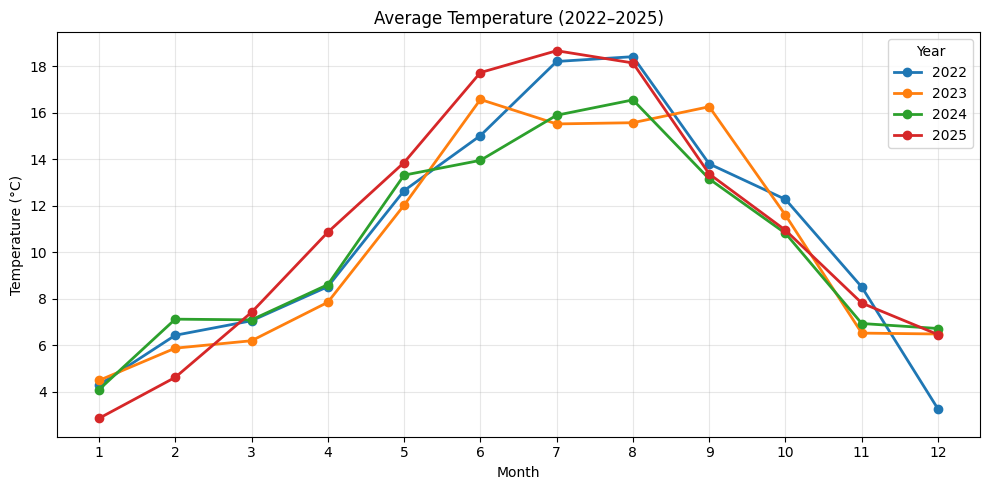

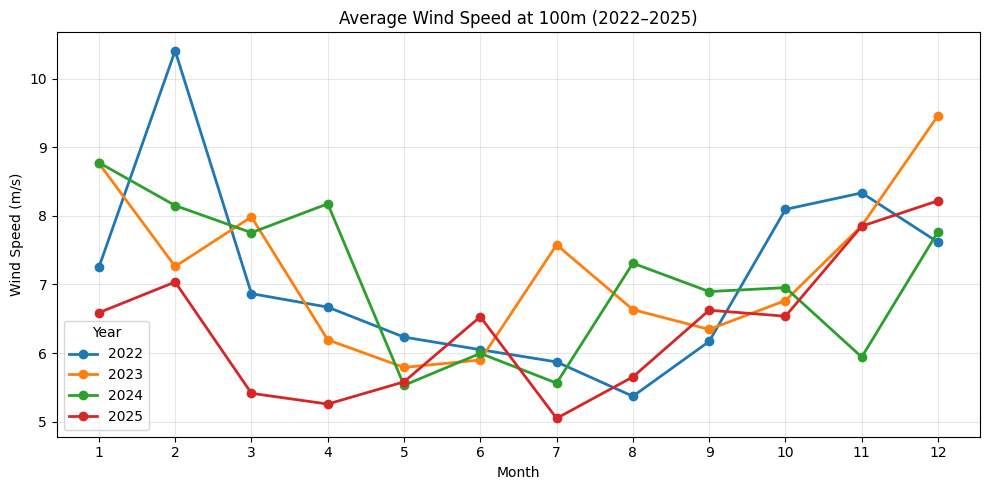

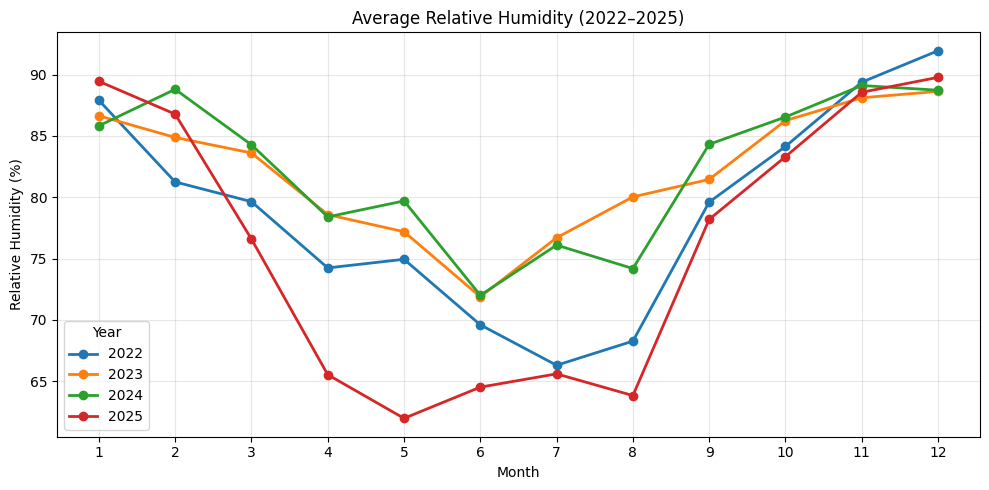

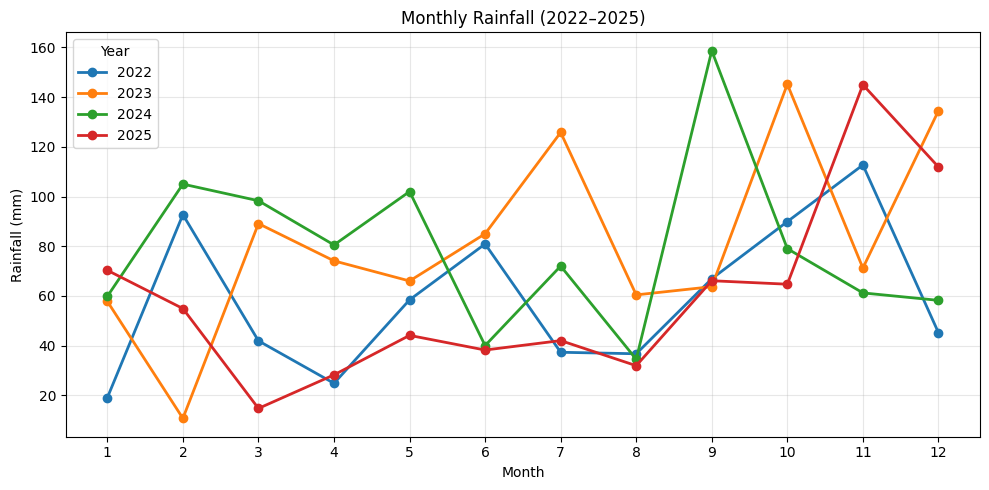

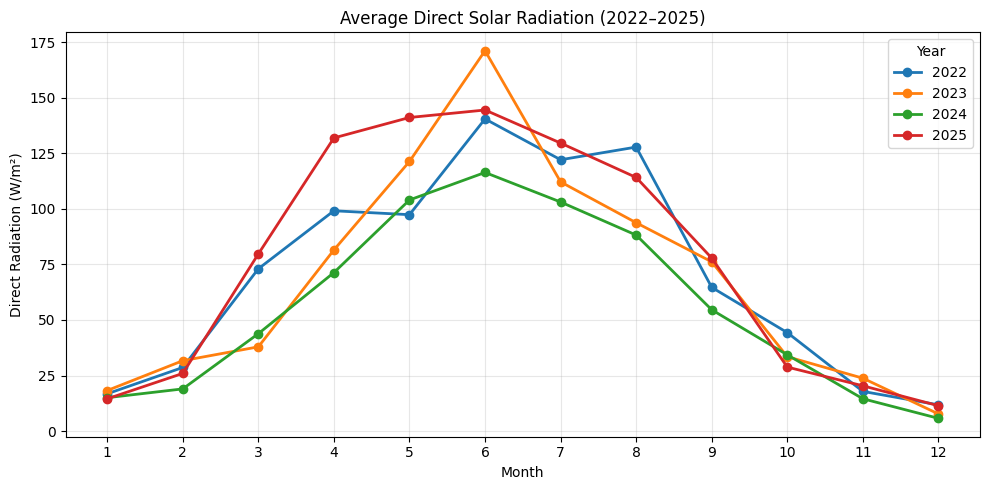

Total data points: 70128

Data points per year:
year
2022    17520
2023    17520
2024    17568
2025    17520
dtype: int64

Missing values:
time                    0
temperature_2m          1
wind_speed_100m         1
relative_humidity_2m    1
rain                    0
direct_radiation        1
year                    0
month                   0
UK_time                 0
dtype: int64


In [ ]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 52.4862,
    "longitude": -1.8904,
    "start_date": "2022-01-01",
    "end_date": "2026-01-01",  # Extra hour to interpolate final 23:30
    "hourly": [
        "temperature_2m",
        "wind_speed_100m",
        "relative_humidity_2m",
        "rain",
        "direct_radiation"
    ],
    "wind_speed_unit": "ms",
    "timezone": "GMT"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()
data = response.json()

# Convert to dataframe
weather = pd.DataFrame(data["hourly"])
weather["time"] = pd.to_datetime(weather["time"], utc=True)

weather = weather.sort_values("time")
weather = weather.drop_duplicates(subset="time")

print("Original hourly weather data:")
display(weather.head())

weather.to_csv("weather_raw_hourly_2022_2025.csv", index=False)

columns = [
    "temperature_2m",
    "wind_speed_100m",
    "relative_humidity_2m",
    "rain",
    "direct_radiation"
]

weather_hourly = weather.set_index("time")[columns]

# Complete half-hourly UTC timeline
half_hour_index = pd.date_range(
    start="2022-01-01 00:00:00",
    end="2025-12-31 23:30:00",
    freq="30min",
    tz="UTC"
)

weather_half_hourly = weather_hourly.reindex(half_hour_index)
weather_half_hourly.index.name = "time"

# Interpolate continuous weather parameters
continuous = [
    "temperature_2m",
    "wind_speed_100m",
    "relative_humidity_2m",
    "direct_radiation"
]

weather_half_hourly[continuous] = (
    weather_half_hourly[continuous]
    .interpolate(method="time", limit=1, limit_area="inside")
)

# Rainfall is an hourly total, not an instantaneous measurement.
# Split each hourly total equally between its two half-hour intervals.
hourly_rain = weather_hourly["rain"].reindex(
    half_hour_index.floor("h")
)

weather_half_hourly["rain"] = hourly_rain.to_numpy() / 2

# Reset index
weather_half_hourly = weather_half_hourly.reset_index()

# Add calendar variables
weather_half_hourly["year"] = weather_half_hourly["time"].dt.year
weather_half_hourly["month"] = weather_half_hourly["time"].dt.month

# Add local UK timestamp for daylight-saving checks
weather_half_hourly["UK_time"] = (
    weather_half_hourly["time"].dt.tz_convert("Europe/London")
)

print("\nHALF-HOURLY WEATHER DATA")
display(weather_half_hourly.head(20))


print("\nOBSERVATIONS PER YEAR:")
print(weather_half_hourly.groupby("year").size())

print("\nMISSING VALUES:")
print(weather_half_hourly.isna().sum())

print("\nTIMESTAMP DIFFERENCES:")
print(weather_half_hourly["time"].diff().value_counts())

expected_counts = {
    2022: 17520,
    2023: 17520,
    2024: 17568,
    2025: 17520
}

actual_counts = weather_half_hourly.groupby("year").size()

for year, expected in expected_counts.items():
    actual = actual_counts.get(year, 0)
    print(f"{year}: {actual} rows (expected {expected})")
    assert actual == expected, f"Incorrect row count for {year}"

print("\nDAYLIGHT-SAVING CHECKS:")

# Local UK days have 46 or 50 half-hourly observations
daily_counts = weather_half_hourly.groupby(
    weather_half_hourly["UK_time"].dt.date
).size()

clock_change_dates = [
    "2022-03-27", "2022-10-30",
    "2023-03-26", "2023-10-29",
    "2024-03-31", "2024-10-27",
    "2025-03-30", "2025-10-26"
]

for date in clock_change_dates:
    count = daily_counts.loc[pd.Timestamp(date).date()]
    print(f"{date}: {count} observations")


yearly_summary = weather_half_hourly.groupby("year").agg(
    average_temperature_C=("temperature_2m", "mean"),
    average_wind_speed_ms=("wind_speed_100m", "mean"),
    average_humidity_percent=("relative_humidity_2m", "mean"),
    total_rainfall_mm=("rain", "sum"),
    average_direct_radiation_Wm2=("direct_radiation", "mean")
).round(2)

print("\nYEARLY WEATHER SUMMARY:")
display(yearly_summary)



monthly = weather_half_hourly.groupby(
    ["year", "month"]
).agg(
    temperature_2m=("temperature_2m", "mean"),
    wind_speed_100m=("wind_speed_100m", "mean"),
    relative_humidity_2m=("relative_humidity_2m", "mean"),
    rain=("rain", "sum"),
    direct_radiation=("direct_radiation", "mean")
).reset_index()

print("\nMONTHLY WEATHER SUMMARY:")
display(monthly.head(12))


parameters = {
    "temperature_2m": (
        "Average Temperature (2022–2025)",
        "Temperature (°C)"
    ),
    "wind_speed_100m": (
        "Average Wind Speed at 100m (2022–2025)",
        "Wind Speed (m/s)"
    ),
    "relative_humidity_2m": (
        "Average Relative Humidity (2022–2025)",
        "Relative Humidity (%)"
    ),
    "rain": (
        "Monthly Rainfall (2022–2025)",
        "Rainfall (mm)"
    ),
    "direct_radiation": (
        "Average Direct Solar Radiation (2022–2025)",
        "Direct Radiation (W/m²)"
    )
}

for column, (title, ylabel) in parameters.items():

    plt.figure(figsize=(10, 5))

    for year in [2022, 2023, 2024, 2025]:
        subset = monthly[monthly["year"] == year]

        plt.plot(
            subset["month"],
            subset[column],
            marker="o",
            linewidth=2,
            label=str(year)
        )

    plt.title(title)
    plt.xlabel("Month")
    plt.ylabel(ylabel)
    plt.xticks(range(1, 13))
    plt.legend(title="Year")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Total number of observations
print("Total data points:", len(weather_half_hourly))

# Number of observations per year
print("\nData points per year:")
print(weather_half_hourly.groupby("year").size())

# Check missing values in each column
print("\nMissing values:")
print(weather_half_hourly.isna().sum())
